# Part 1. Dataset and feature engineering

Question: choose a dataset with numeric and text fields, then clean it, scale it, encode categories, and reduce dimensions where that helps.

Dataset: [Airlines Review Dataset](https://www.kaggle.com/datasets/elijahconnectng/airlines-review-dataset). File: `data/airlines_reviews.csv`.

This notebook is self-contained. The same cleaning is repeated at the top of the other question notebooks. The combined write-up is `airline_reviews_ml.ipynb`.

## Setup

In [1]:
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
if not (ROOT / "data" / "airlines_reviews.csv").exists():
    ROOT = Path(r"C:\Users\rdram\OneDrive\Desktop\Machine Learning\CA_machine_learning")

DATA_PATH = ROOT / "data" / "airlines_reviews.csv"
FIG = ROOT / "figures" / "part1"
OUT = ROOT / "outputs" / "part1"
FIG.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

RATING_COLS = [
    "Seat Comfort", "Staff Service", "Food & Beverages",
    "Inflight Entertainment", "Value For Money", "Overall Rating",
]
SERVICE_COLS = [
    "Seat Comfort", "Staff Service", "Food & Beverages", "Inflight Entertainment",
]
RANDOM_STATE = 42


def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    plt.show()


def silhouette_safe(X, labels):
    # Silhouette on non-noise points. NaN when a partition is not valid.
    labels = np.asarray(labels)
    mask = labels != -1
    y = labels[mask]
    if len(y) < 3 or len(np.unique(y)) < 2:
        return np.nan
    _, counts = np.unique(y, return_counts=True)
    if counts.min() < 2:
        return np.nan
    return float(silhouette_score(X[mask], y, n_jobs=-1))


print("Question folder:", FIG.parent.name + "/" + FIG.name)
print("Data file:", DATA_PATH)

Question folder: figures/part1
Data file: C:\Users\rdram\OneDrive\Desktop\Machine Learning\CA_machine_learning\data\airlines_reviews.csv


## Load

In [ ]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
print("Columns:", list(raw.columns))
display(raw.head(3))
display(raw[RATING_COLS].agg(["min", "max", "mean", "std"]).round(3))
print("Missing values:", int(raw.isnull().sum().sum()))
print("Airlines:", raw["Airline"].nunique(), "| classes:", raw["Class"].nunique(), "| routes:", raw["Route"].nunique())

## Exploratory checks

Overall rating uses 1–10. The service scores use 1–5. Route has thousands of levels, so it is not one-hot encoded later. The bar charts show whether scores pile up at the extremes, which matters for clustering.

Duplicate rows: 0
Duplicate review texts: 1
Verified values:


,reviews
Verified,
True,6216
False,1881
*Unverified*,1
NotVerified,1
we do appreciate you bringing this matter to our attention. Please accept my apologies for not having met your expectations; I do hope that we can leave you and your family with a more positive impression on your future flights with us,1


Share of overall ratings in 1, 2, 9 or 10: 63.8%


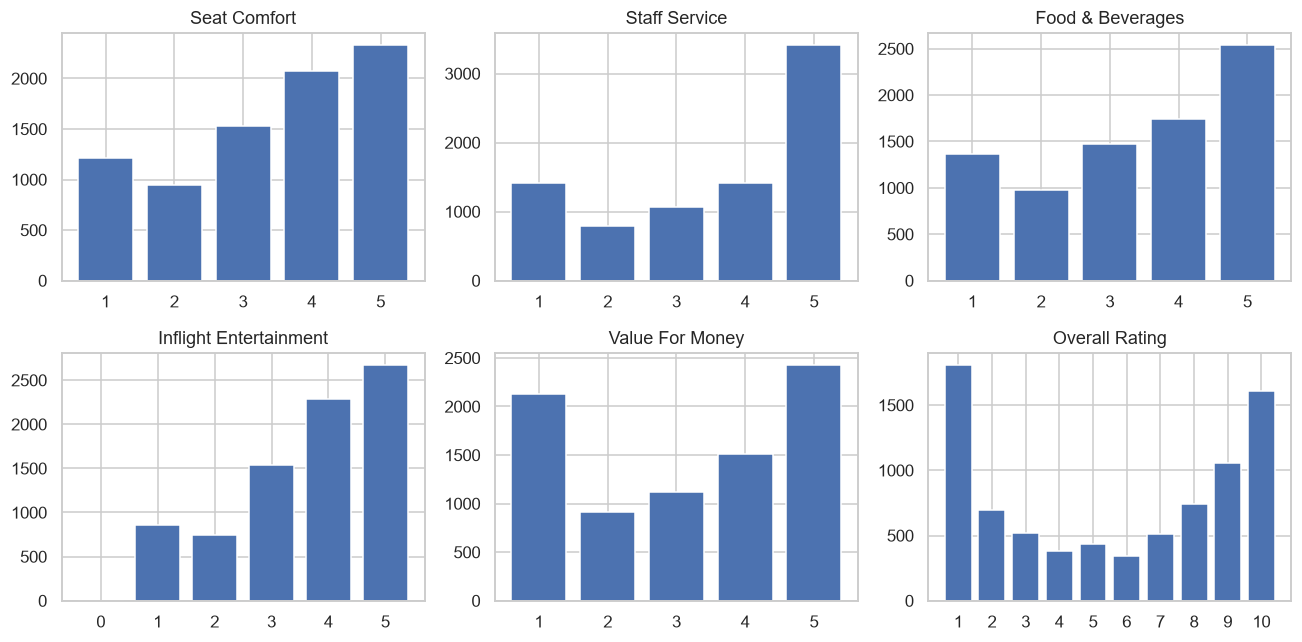

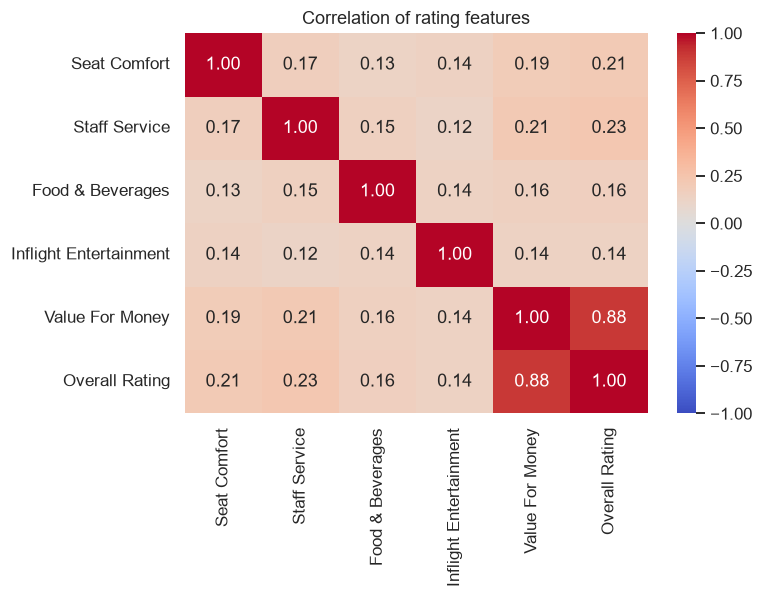

Value For Money vs Overall Rating: 0.883


In [3]:
print("Duplicate rows:", int(raw.duplicated().sum()))
print("Duplicate review texts:", int(raw["Reviews"].duplicated().sum()))
print("Verified values:")
display(raw["Verified"].value_counts().to_frame("reviews"))
extreme_share = raw["Overall Rating"].isin([1, 2, 9, 10]).mean()
print(f"Share of overall ratings in 1, 2, 9 or 10: {extreme_share:.1%}")

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.ravel(), RATING_COLS):
    values = raw[col].value_counts().sort_index()
    ax.bar(values.index.astype(str), values.values, color="#4C72B0")
    ax.set_title(col)
save_fig(fig, "rating_distributions.png")

corr = raw[RATING_COLS].corr()
fig, ax = plt.subplots(figsize=(7.2, 5.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation of rating features")
save_fig(fig, "correlation_heatmap.png")
print("Value For Money vs Overall Rating:", round(float(corr.loc["Value For Money", "Overall Rating"]), 3))

## Cleaning

`Verified` has three bad entries. Those rows still have a real review and real scores, so the flag is set to False. One inflight-entertainment value is 0, outside the 1–5 scale, and is replaced by the median of the valid scores. Exact duplicate reviews are removed.

The interquartile screen is computed to show that scores of 1 and 5 (or 10) are not outliers on this bounded scale. They are kept.

In [4]:
raw = pd.read_csv(DATA_PATH)
df = raw.copy()
text_cols = [col for col in df.columns if pd.api.types.is_string_dtype(df[col])]
for col in text_cols:
    df[col] = df[col].str.replace("\xa0", " ", regex=False).str.strip()

verified_map = {
    "True": "True", "False": "False", "*Unverified*": "False", "NotVerified": "False",
}
n_verified_fixed = int((~df["Verified"].isin(["True", "False"])).sum())
df["Verified"] = df["Verified"].map(verified_map).fillna("False")

ife = df["Inflight Entertainment"]
n_ife_zero = int((ife == 0).sum())
ife_median = float(ife[ife > 0].median())
df.loc[ife == 0, "Inflight Entertainment"] = ife_median

n_dups = int(df["Reviews"].duplicated().sum())
df = df.drop_duplicates(subset=["Reviews"]).reset_index(drop=True)

df["Month Flown Date"] = pd.to_datetime(df["Month Flown"], format="%B %Y")
df["Year Flown"] = df["Month Flown Date"].dt.year
df["Year Bin"] = pd.cut(
    df["Year Flown"],
    bins=[2012, 2016, 2019, 2021, 2025],
    labels=["2013-2016", "2017-2019", "2020-2021", "2022-2024"],
).astype(str)
df["Review Length"] = df["Reviews"].str.len()

print(f"Rows before cleaning: {len(raw):,}")
print(f"Rows after cleaning:  {len(df):,}")
print(f"Verified flags corrected: {n_verified_fixed}")
print(f"Inflight Entertainment zeros imputed with median {ife_median:.0f}: {n_ife_zero}")
print(f"Duplicate reviews removed: {n_dups}")

Rows before cleaning: 8,100
Rows after cleaning:  8,098
Verified flags corrected: 3
Inflight Entertainment zeros imputed with median 4: 1
Duplicate reviews removed: 2


,feature,lower,upper,iqr_flags
0,Seat Comfort,-2.50,9.50,0
1,Staff Service,-2.50,9.50,0
2,Food & Beverages,-2.50,9.50,0
3,Inflight Entertainment,0.00,8.00,0
4,Value For Money,-5.00,11.00,0
5,Overall Rating,-8.50,19.50,0
6,Review Length,-515.62,1979.38,427


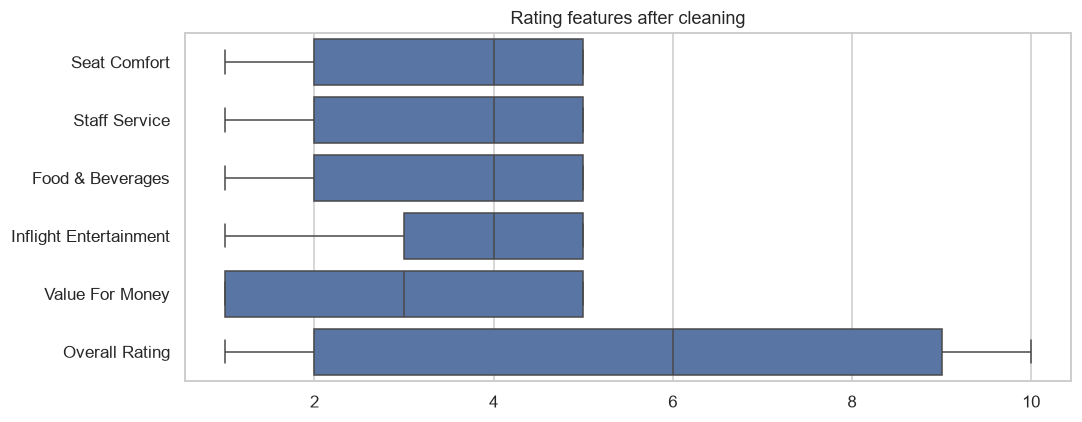

In [5]:
iqr_rows = []
for col in RATING_COLS + ["Review Length"]:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_flag = int(((df[col] < lo) | (df[col] > hi)).sum())
    iqr_rows.append({"feature": col, "lower": lo, "upper": hi, "iqr_flags": n_flag})
iqr_table = pd.DataFrame(iqr_rows)
display(iqr_table.round(2))
iqr_table.to_csv(OUT / "iqr_screen.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=df[RATING_COLS], orient="h", ax=ax, color="#4C72B0")
ax.set_title("Rating features after cleaning")
save_fig(fig, "rating_boxplots.png")

## Scaling, binning, one-hot encoding, PCA

Standardisation:

\[
z = \frac{x - \mu}{\sigma}
\]

Overall rating has a wider range than the 1–5 scores. K-Means, Ward linkage, and DBSCAN all use Euclidean distance, so the wider column would dominate if the raw numbers were used. `StandardScaler` uses the population standard deviation (`ddof=0`).

Year flown is binned into 2013–2016, 2017–2019, 2020–2021, and 2022–2024, then one-hot encoded with airline, cabin class, and traveller type. `Recommended` is not an input feature. PCA keeps 90% of the variance of the mixed matrix. A separate 2-component PCA is only for plotting the ratings.

In [6]:
def scale_frame(frame, cols):
    scaler = StandardScaler()
    return scaler.fit_transform(frame[cols]), scaler


X_main, scaler_main = scale_frame(df, RATING_COLS)
X_no_overall, _ = scale_frame(df, [c for c in RATING_COLS if c != "Overall Rating"])
X_service, _ = scale_frame(df, SERVICE_COLS)

scale_table = pd.DataFrame({
    "feature": RATING_COLS,
    "mean": scaler_main.mean_,
    "std": scaler_main.scale_,
})
display(scale_table.round(3))
scale_table.round(6).to_csv(OUT / "standard_scaler_parameters.csv", index=False)

example_raw = df.loc[0, RATING_COLS].to_numpy(dtype=float)
example_z = (example_raw - scaler_main.mean_) / scaler_main.scale_
example_check = scaler_main.transform(df.loc[[0], RATING_COLS])[0]
worked = pd.DataFrame({
    "feature": RATING_COLS,
    "raw_x": example_raw,
    "mean": scaler_main.mean_,
    "std": scaler_main.scale_,
    "z_manual": example_z,
    "z_scaler": example_check,
})
print("Worked standardisation for review 0. z = (x - mean) / std")
display(worked.round(4))
print("Max gap between manual z and StandardScaler:", float(np.max(np.abs(example_z - example_check))))

encoder = OneHotEncoder(sparse_output=False, dtype=np.float64)
cat_cols = ["Airline", "Class", "Type of Traveller", "Year Bin"]
X_cat = encoder.fit_transform(df[cat_cols])
X_mixed = np.hstack([X_main, X_cat])
pca_mixed = PCA(n_components=0.90, random_state=RANDOM_STATE)
X_mixed_pca = pca_mixed.fit_transform(X_mixed)

pca_viz = PCA(n_components=2, random_state=RANDOM_STATE)
XY = pca_viz.fit_transform(X_main)
loadings = pd.DataFrame(pca_viz.components_.T, index=RATING_COLS, columns=["PC1", "PC2"])
print("PCA loadings on the 6 standardised ratings:")
display(loadings.round(3))
print(
    f"PC1 + PC2 explain {pca_viz.explained_variance_ratio_.sum():.1%} of rating variance. "
    f"Mixed-feature PCA kept {X_mixed_pca.shape[1]} components "
    f"({pca_mixed.explained_variance_ratio_.sum():.1%} variance)."
)
loadings.round(4).to_csv(OUT / "pca_loadings.csv")

,feature,mean,std
0,Seat Comfort,3.415,1.397
1,Staff Service,3.570,1.527
2,Food & Beverages,3.384,1.455
3,Inflight Entertainment,3.637,1.309
4,Value For Money,3.149,1.589
5,Overall Rating,5.632,3.523


Worked standardisation for review 0. z = (x - mean) / std


,feature,raw_x,mean,std,z_manual,z_scaler
0,Seat Comfort,4.0,3.4149,1.3969,0.4188,0.4188
1,Staff Service,4.0,3.5699,1.5273,0.2816,0.2816
2,Food & Beverages,4.0,3.3842,1.4554,0.4231,0.4231
3,Inflight Entertainment,4.0,3.6371,1.3089,0.2773,0.2773
4,Value For Money,4.0,3.1486,1.5893,0.5357,0.5357
5,Overall Rating,9.0,5.6324,3.5233,0.9558,0.9558


Max gap between manual z and StandardScaler: 0.0
PCA loadings on the 6 standardised ratings:


,PC1,PC2
Seat Comfort,0.292,0.368
Staff Service,0.309,0.318
Food & Beverages,0.249,0.473
Inflight Entertainment,0.228,0.514
Value For Money,0.591,-0.379
Overall Rating,0.597,-0.363


PC1 + PC2 explain 55.3% of rating variance. Mixed-feature PCA kept 13 components (91.5% variance).


Worked PCA score for review 0, scaled ratings dotted with the loadings:
  manual  [1.2648 0.0363]
  sklearn [1.2648 0.0363]


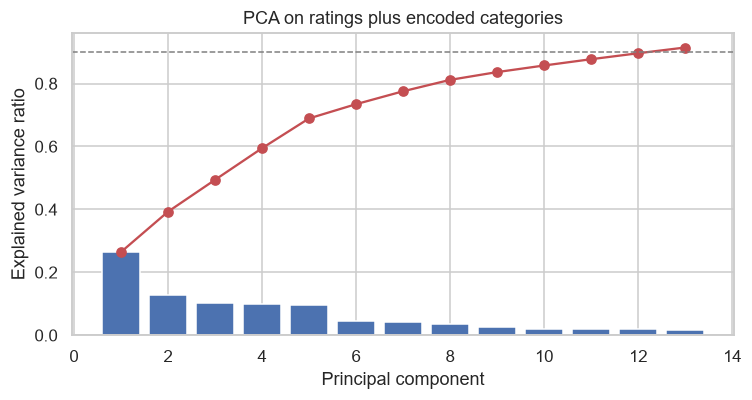

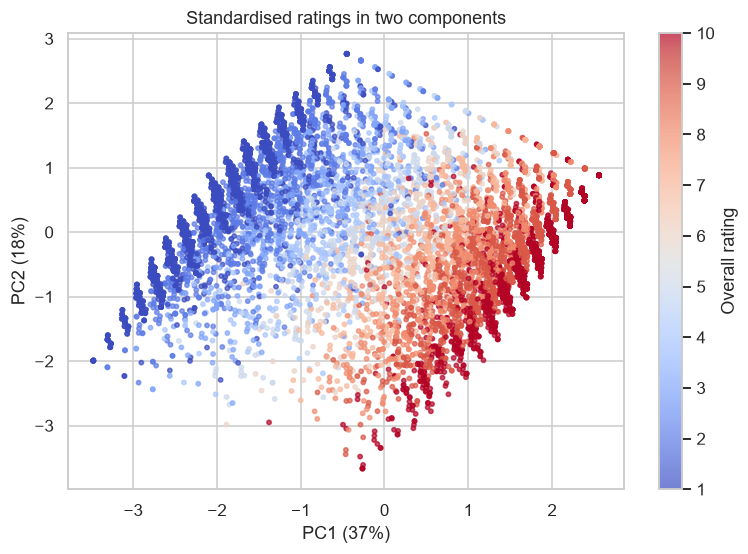

K-Means silhouette after each feature choice (K re-selected in that space):


,feature_space,best_k,silhouette
0,6 ratings (main),2,0.2708
1,"5 ratings, no overall",2,0.2244
2,4 service scores only,8,0.2610
3,Mixed features + PCA 90%,2,0.2085


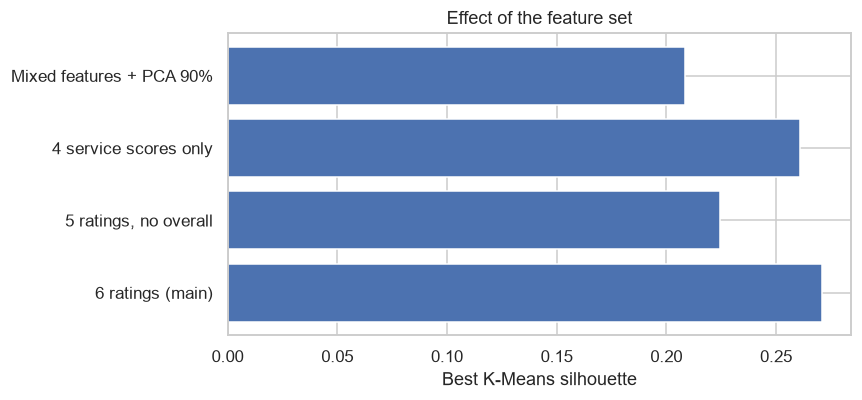

In [7]:
pc_manual = example_z @ pca_viz.components_.T
pc_sklearn = pca_viz.transform(example_z.reshape(1, -1))[0]
print("Worked PCA score for review 0, scaled ratings dotted with the loadings:")
print("  manual ", np.round(pc_manual, 4))
print("  sklearn", np.round(pc_sklearn, 4))

fig, ax = plt.subplots(figsize=(7, 3.8))
ratios = pca_mixed.explained_variance_ratio_
ax.bar(np.arange(1, len(ratios) + 1), ratios, color="#4C72B0")
ax.plot(np.arange(1, len(ratios) + 1), np.cumsum(ratios), color="#C44E52", marker="o")
ax.axhline(0.90, color="gray", ls="--", lw=1)
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_title("PCA on ratings plus encoded categories")
save_fig(fig, "pca_scree.png")

fig, ax = plt.subplots(figsize=(7.2, 5.2))
sc = ax.scatter(XY[:, 0], XY[:, 1], c=df["Overall Rating"], cmap="coolwarm", s=8, alpha=0.7)
fig.colorbar(sc, ax=ax, label="Overall rating")
ax.set_xlabel(f"PC1 ({pca_viz.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"PC2 ({pca_viz.explained_variance_ratio_[1]:.0%})")
ax.set_title("Standardised ratings in two components")
save_fig(fig, "pca_scatter_rating.png")

feature_sets = {
    "6 ratings (main)": X_main,
    "5 ratings, no overall": X_no_overall,
    "4 service scores only": X_service,
    "Mixed features + PCA 90%": X_mixed_pca,
}
feat_rows = []
for name, matrix in feature_sets.items():
    best = None
    for k in range(2, 9):
        labels = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(matrix)
        sil = silhouette_safe(matrix, labels)
        if best is None or sil > best["silhouette"]:
            best = {"feature_space": name, "best_k": k, "silhouette": sil}
    feat_rows.append(best)
feat_table = pd.DataFrame(feat_rows)
print("K-Means silhouette after each feature choice (K re-selected in that space):")
display(feat_table.round(4))
feat_table.to_csv(OUT / "feature_set_comparison.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(feat_table["feature_space"], feat_table["silhouette"], color="#4C72B0")
ax.set_xlabel("Best K-Means silhouette")
ax.set_title("Effect of the feature set")
save_fig(fig, "feature_set_comparison.png")

## Part 1 answer

Cleaning keeps every in-range rating, fixes three `Verified` flags, imputes one entertainment zero, and drops duplicate review text. Standardisation is the scaling step, shown for review 0. Binning is applied to year flown. One-hot encoding is applied to airline, class, traveller type, and the year bin. PCA then compresses that wider matrix to 90% of its variance. The feature-set table is the numeric evidence that the six standardised ratings are a clearer clustering space than the mixed one-hot matrix.